In [10]:
import pandas  as pd 
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [6]:
data = fetch_california_housing(as_frame=True)
df = data.frame
#print(df.head())
#print(df.info())
print(df.describe())

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.692308     32.54000

In [9]:
x = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size = 0.2 , random_state = 42)

In [11]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
model = LinearRegression()
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')


Mean Squared Error: 0.555891598695244
R-squared: 0.5757877060324511


In [12]:
for name  , w in zip(x.columns, model.coef_):
    print(f'{name:12s}: {w:.3f}')
print(f'Intercept: {model.intercept_:.3f}') 

MedInc      : 0.854
HouseAge    : 0.123
AveRooms    : -0.294
AveBedrms   : 0.339
Population  : -0.002
AveOccup    : -0.041
Latitude    : -0.897
Longitude   : -0.870
Intercept: 2.072


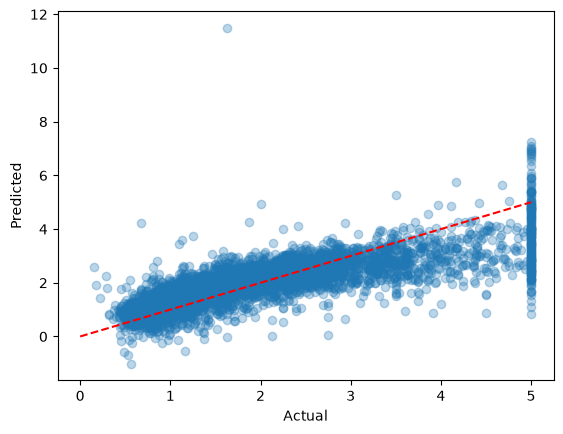

In [14]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.show()